In [1]:

import csv
from pathlib import Path

archivo = Path("ventas_ejemplo.csv")

if archivo.exists():
    print("Archivo encontrado correctamente")
else:
    print("No se encontró el archivo CSV")

Archivo encontrado correctamente



# Taller 04: Diseño de Arquitectura de Datos para Yachay-Shop

**Universidad:** Yachay Tech  
**Programa:** Maestría en Ciencia de Datos  
**Tema:** Arquitectura de Datos para un E-Commerce

## 1. Introducción

Yachay-Shop es una empresa de comercio electrónico que opera mediante una página web, una aplicación móvil y tiendas físicas.

Para mejorar la gestión de la información, se propone una arquitectura híbrida que combina un Data Lake y un Data Warehouse.

Como complemento al diseño HLD, se desarrollará una demostración sencilla en Python para procesar datos de ventas provenientes de diferentes canales comerciales.

## 2. Objetivo de la demostración

Aplicar un proceso básico de extracción, transformación y carga (ETL) sobre un archivo CSV de ventas.

### Actividades

- Leer los datos de ventas.
- Explorar y validar la información.
- Calcular unidades vendidas e ingresos por canal.
- Visualizar los resultados.
- Exportar un resumen consolidado.

**Alcance:** Esta demostración representa únicamente el procesamiento por lotes de la arquitectura propuesta.



## 3. Importación de librerías

Para desarrollar la demostración se utilizarán las siguientes librerías de Python:

- **csv:** permite leer y procesar archivos CSV que contienen información de ventas.
- **pathlib:** facilita la gestión de rutas y la ubicación de archivos.
- **collections:** permite agrupar y acumular información para generar resúmenes.

Estas herramientas forman parte de la biblioteca estándar de Python, por lo que no requieren instalaciones adicionales.


In [2]:

# Importación de librerías

import csv
from pathlib import Path
from collections import defaultdict

print("Librerías importadas correctamente")


Librerías importadas correctamente



## 4. Lectura de los datos de ventas

En esta etapa se realiza la extracción de información desde el archivo `ventas_ejemplo.csv`.

El archivo contiene registros de ventas de Yachay-Shop correspondientes a diferentes canales comerciales.

Se utilizará la librería `csv` para leer los registros y almacenarlos en una lista de Python.

Esta actividad representa la fase de **extracción (Extract)** dentro del proceso ETL propuesto en la arquitectura de datos.


In [3]:

# Lectura del archivo de ventas

ruta_archivo = Path("ventas_ejemplo.csv")

with open(ruta_archivo, "r", encoding="utf-8-sig", newline="") as archivo:
    lector = csv.DictReader(archivo)
    ventas = list(lector)

print("Archivo leído correctamente")
print("Total de registros:", len(ventas))

print("\nColumnas del archivo:")
print(lector.fieldnames)

print("\nPrimer registro:")
print(ventas[0] if ventas else "No hay registros")


Archivo leído correctamente
Total de registros: 5

Columnas del archivo:
['id_venta', 'fecha', 'canal', 'producto', 'cantidad', 'precio_unitario']

Primer registro:
{'id_venta': 'V001', 'fecha': '2026-10-01', 'canal': 'Web', 'producto': 'Televisor', 'cantidad': '1', 'precio_unitario': '450.00'}



## 5. Exploración y validación de los datos

Una vez extraída la información del archivo CSV, se procede a revisar la calidad de los registros.

El objetivo es identificar posibles errores que puedan afectar el análisis de ventas.

Se comprobará que:

- Los registros contengan los campos obligatorios.
- La cantidad vendida sea un número entero mayor que cero.
- El precio unitario sea un número válido y no negativo.
- El canal de venta esté identificado.

Esta actividad forma parte de la etapa de **transformación (Transform)** del proceso ETL, ya que permite preparar datos confiables para su posterior análisis.


In [4]:

# Exploración y validación de las ventas

from decimal import Decimal, InvalidOperation

ventas_validas = []
ventas_invalidas = []

campos_obligatorios = [
    "id_venta", "fecha", "canal",
    "producto", "cantidad", "precio_unitario"
]

for numero, venta in enumerate(ventas, start=1):
    try:
        # Verificar campos obligatorios
        if any(
            not (venta.get(campo) or "").strip()
            for campo in campos_obligatorios
        ):
            raise ValueError("Existen campos vacíos")

        # Convertir valores numéricos
        cantidad = int(venta["cantidad"])
        precio = Decimal(venta["precio_unitario"])

        # Verificar valores permitidos
        if cantidad <= 0 or not precio.is_finite() or precio < 0:
            raise ValueError("Cantidad o precio no válido")

        # Preparar el registro para el análisis
        venta_limpia = venta.copy()
        venta_limpia["cantidad"] = cantidad
        venta_limpia["precio_unitario"] = precio
        venta_limpia["total_venta"] = cantidad * precio

        ventas_validas.append(venta_limpia)

    except (ValueError, InvalidOperation, TypeError) as error:
        ventas_invalidas.append({
            "fila": numero,
            "motivo": str(error)
        })

print("Total de registros:", len(ventas))
print("Registros válidos:", len(ventas_validas))
print("Registros inválidos:", len(ventas_invalidas))

print("\nDatos preparados para el análisis:")

for venta in ventas_validas:
    print(
        venta["canal"],
        "|", venta["producto"],
        "| Unidades:", venta["cantidad"],
        "| Total: $", venta["total_venta"]
    )


Total de registros: 5
Registros válidos: 5
Registros inválidos: 0

Datos preparados para el análisis:
Web | Televisor | Unidades: 1 | Total: $ 450.00
Tienda | Refrigeradora | Unidades: 1 | Total: $ 620.00
App | Audifonos | Unidades: 2 | Total: $ 71.00
Web | Audifonos | Unidades: 1 | Total: $ 35.50
Tienda | Televisor | Unidades: 1 | Total: $ 450.00



## 6. Agrupación y análisis de ventas por canal

Una vez validados los registros, se procede a consolidar la información de ventas según el canal comercial.

El objetivo es conocer:

- La cantidad de unidades vendidas por canal.
- Los ingresos generados por cada canal.
- El total general de unidades e ingresos.

Este procedimiento permite transformar registros individuales en información resumida para apoyar la toma de decisiones.

En la arquitectura propuesta para Yachay-Shop, esta información podría almacenarse en el Data Warehouse y utilizarse posteriormente en herramientas de inteligencia empresarial como Power BI.


In [5]:

# Agrupación de ventas por canal

resumen_canales = defaultdict(
    lambda: {"unidades": 0, "ingresos": Decimal("0.00")}
)

for venta in ventas_validas:
    canal = venta["canal"]

    resumen_canales[canal]["unidades"] += venta["cantidad"]
    resumen_canales[canal]["ingresos"] += venta["total_venta"]

# Calcular totales generales
total_unidades = sum(
    datos["unidades"] for datos in resumen_canales.values()
)

total_ingresos = sum(
    (datos["ingresos"] for datos in resumen_canales.values()),
    Decimal("0.00")
)

# Mostrar resultados
print("RESUMEN DE VENTAS POR CANAL")
print("-" * 53)

for canal, datos in sorted(resumen_canales.items()):
    print(
        f"{canal:<12} "
        f"Unidades: {datos['unidades']:<3} "
        f"Ingresos: ${datos['ingresos']:,.2f}"
    )

print("-" * 53)
print(f"TOTAL UNIDADES: {total_unidades}")
print(f"TOTAL INGRESOS: ${total_ingresos:,.2f}")


RESUMEN DE VENTAS POR CANAL
-----------------------------------------------------
App          Unidades: 2   Ingresos: $71.00
Tienda       Unidades: 2   Ingresos: $1,070.00
Web          Unidades: 2   Ingresos: $485.50
-----------------------------------------------------
TOTAL UNIDADES: 6
TOTAL INGRESOS: $1,626.50



## 7. Visualización de las ventas por canal

Después de consolidar las ventas, se procede a representar gráficamente los ingresos obtenidos por cada canal comercial.

El objetivo es facilitar la comparación del rendimiento de los canales Web, App y Tienda física.

Para ello, se utilizará la librería Matplotlib de Python, que permite elaborar gráficos para el análisis de información.

Esta visualización representa una aplicación sencilla de inteligencia de negocios, similar a los reportes que podrían desarrollarse mediante Power BI en la arquitectura propuesta.

Los datos utilizados son ficticios y tienen fines académicos.


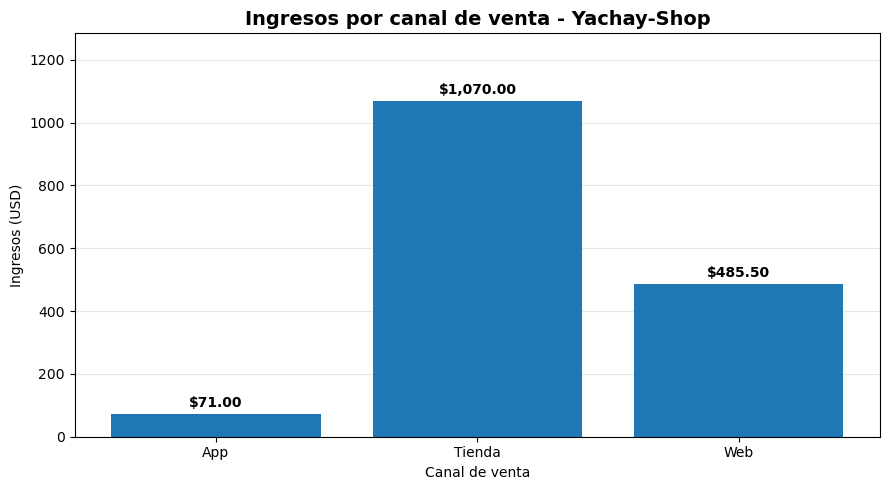

In [6]:

# Visualización de ingresos por canal

import matplotlib.pyplot as plt

# Preparar los datos
canales = sorted(resumen_canales.keys())

ingresos = [
    float(resumen_canales[canal]["ingresos"])
    for canal in canales
]

# Crear gráfico
fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.bar(canales, ingresos)

# Títulos y etiquetas
ax.set_title(
    "Ingresos por canal de venta - Yachay-Shop",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Canal de venta")
ax.set_ylabel("Ingresos (USD)")

# Mostrar valores sobre cada barra
for barra in barras:
    altura = barra.get_height()

    ax.annotate(
        f"${altura:,.2f}",
        xy=(barra.get_x() + barra.get_width() / 2, altura),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

# Mejorar presentación
ax.set_ylim(0, max(ingresos) * 1.20)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



## 8. Exportación de resultados

Una vez procesados y analizados los datos de ventas, se procede a almacenar los resultados en un nuevo archivo CSV.

El objetivo es generar un resumen consolidado que pueda utilizarse posteriormente en herramientas de inteligencia empresarial.

El archivo contendrá:

- Canal de venta.
- Unidades vendidas.
- Ingresos totales.

Esta actividad representa la fase de **carga (Load)** del proceso ETL.

En la arquitectura HLD de Yachay-Shop, los datos consolidados podrían cargarse en Amazon Redshift para su posterior análisis mediante Power BI.

En esta demostración académica se utilizará un archivo CSV como destino, sin necesidad de conectarse a servicios en la nube.


In [7]:

# Exportación del resumen de ventas

from pathlib import Path
import csv

# Crear carpeta de resultados
carpeta_resultados = Path("resultados")
carpeta_resultados.mkdir(exist_ok=True)

# Definir archivo de salida
archivo_salida = carpeta_resultados / "resumen_por_canal.csv"

# Guardar resultados
with open(archivo_salida, "w", newline="", encoding="utf-8") as archivo:
    escritor = csv.writer(archivo)

    escritor.writerow(["canal", "unidades", "ingresos"])

    for canal, datos in sorted(resumen_canales.items()):
        escritor.writerow([
            canal,
            datos["unidades"],
            f"{datos['ingresos']:.2f}"
        ])

print("Archivo exportado correctamente")
print("Ubicación:", archivo_salida)


Archivo exportado correctamente
Ubicación: resultados\resumen_por_canal.csv



## 9. Verificación de los resultados exportados

Después de generar el archivo de resultados, se realiza una comprobación para verificar que la información se haya almacenado correctamente.

Esta etapa permite confirmar que los datos procesados mantienen su integridad y que los valores exportados coinciden con los cálculos realizados anteriormente.

Se verificará:

- Que el archivo CSV exista.
- Que contenga los canales comerciales analizados.
- Que las unidades e ingresos coincidan con los resultados calculados.
- Que la información pueda recuperarse para futuros análisis.

Esta verificación representa un control básico de calidad de datos dentro de la arquitectura propuesta para Yachay-Shop.


In [8]:

# Verificación del archivo exportado

with open(archivo_salida, "r", encoding="utf-8", newline="") as archivo:
    lector = csv.DictReader(archivo)
    resultados = list(lector)

# Calcular totales del archivo exportado
unidades_verificadas = sum(
    int(fila["unidades"]) for fila in resultados
)

ingresos_verificados = sum(
    (Decimal(fila["ingresos"]) for fila in resultados),
    Decimal("0.00")
)

# Comprobar que coincidan con los cálculos originales
assert len(resultados) == len(resumen_canales)
assert unidades_verificadas == total_unidades
assert ingresos_verificados == total_ingresos

print("VERIFICACIÓN DEL ARCHIVO CSV")
print("-" * 45)

for fila in resultados:
    print(
        f"Canal: {fila['canal']:<8} "
        f"Unidades: {fila['unidades']:<3} "
        f"Ingresos: ${Decimal(fila['ingresos']):,.2f}"
    )

print("-" * 45)
print("Total de unidades:", unidades_verificadas)
print(f"Total de ingresos: ${ingresos_verificados:,.2f}")
print("\nVerificación completada correctamente")


VERIFICACIÓN DEL ARCHIVO CSV
---------------------------------------------
Canal: App      Unidades: 2   Ingresos: $71.00
Canal: Tienda   Unidades: 2   Ingresos: $1,070.00
Canal: Web      Unidades: 2   Ingresos: $485.50
---------------------------------------------
Total de unidades: 6
Total de ingresos: $1,626.50

Verificación completada correctamente



## 10. Relación de la demostración con la arquitectura HLD

La demostración desarrollada en Python representa una versión simplificada del procesamiento por lotes propuesto para Yachay-Shop.

El ejercicio permite relacionar las actividades realizadas con los componentes de la arquitectura:

| Componente HLD | Aplicación en la demostración |
|---|---|
| Fuentes de datos | Archivo `ventas_ejemplo.csv` |
| Ingestión por lotes | Lectura del archivo mediante Python |
| Transformación | Validación de registros y cálculo de ingresos |
| Procesamiento analítico | Agrupación de ventas por canal |
| Almacenamiento | Exportación a `resumen_por_canal.csv` |
| Inteligencia empresarial | Visualización gráfica mediante Matplotlib |

**Alcance de la demostración:**

El ejercicio no implementa Apache Kafka, Amazon S3, Apache Spark, Amazon Redshift ni Power BI. Estas tecnologías forman parte del diseño conceptual de la arquitectura HLD.

La práctica permite comprobar, a pequeña escala, cómo se procesan los datos antes de utilizarlos para el análisis empresarial.

## 11. Conclusiones

1. Se desarrolló una demostración funcional de procesamiento de datos por lotes utilizando Python, aplicando las etapas de extracción, transformación y carga (ETL).

2. Se comprobó la importancia de validar la información antes del análisis. Los cinco registros procesados cumplieron las condiciones establecidas, sin presentar errores.

3. La consolidación de información permitió identificar que el canal Tienda generó los mayores ingresos, con USD 1.070,00, equivalente aproximadamente al 65,8 % del total de ventas del ejercicio.

4. La visualización de los ingresos por canal facilitó la interpretación de los resultados y permitió identificar diferencias entre el rendimiento de los canales comerciales.

5. La exportación y verificación del archivo CSV demostraron que los resultados procesados pueden almacenarse y recuperarse correctamente.

6. La actividad permitió comprender cómo una arquitectura de datos integra procesos de extracción, validación, transformación, almacenamiento y análisis para apoyar la toma de decisiones empresariales.

## 12. Recomendaciones

- Mantener controles de calidad de datos durante los procesos de integración.
- Automatizar progresivamente los procesos de extracción y transformación.
- Centralizar la información analítica para facilitar la elaboración de reportes.
- Implementar controles de seguridad y acceso a los datos.
- Considerar tecnologías escalables cuando aumenten el volumen y la variedad de la información.
